<a href="https://colab.research.google.com/github/nandhunandhini123/Retail-Store-Sales-Inventory-Performance-Analysis/blob/main/Retail_Store_Sales_%26_Inventory_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Retail Store Sales & Inventory Performance Analysis**

# **Objective(Problem statment)**

1. To analyze retail sales and inventory data using Python.
2. To analyze the impact of price, discount, promotions, weather, and seasonality on sales.
3. To compare sales and inventory performance across stores, products, categories, and regions.
4. To identify possible stock shortage and overstock situations.
5. To generate meaningful insights that can support better inventory planning and decision-making.

# **Outcome**

This project helps to understand how product demand affects sales. and how stores can maintain better inventory levels.

# Domain
Retail / E-commerce

#**Dataset Information**

##### **Source:** Open Data Portals / Kaggle <font color="blue"><u>
**https://www.kaggle.com/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset**</font></u>

**Year / Timeline:** Data collected during 2022 to 2024

**Dataset Column/features Description:**

* **Date**- The date of the sales and inventory record
* **Store ID** -Identifies the store
* **Product ID** -Identifies the specific product.
* **Category** -Shows the category of the product.
* **Region** -Shows the geographical region of the store.
* **Inventory Level** -Number of products available in stock.
* **Units Sold** -Number of units sold.
* **Units Ordered** -Number of units ordered for restocking.
* **Demand Forecast** -Estimated demand for the product.
* **Price** -Selling price of the product.
* **Discount** -Discount percentage offered on the product
* **Weather Condition** -Weather condition on that day.
* **Holiday/Promotion** -Indicates whether a holiday or special offer was active.
* **Competitor Pricing** -Price of a similar product from competitors.
* **Seasonality** -Shows the season associated with the record.

**Data Loading and Initial Overview(EDA)**




In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df=pd.read_csv("retail_store_inventory.csv")
df.head(10) # It Shows the first few rows of the dataset.

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer
5,2022-01-01,S001,P0006,Groceries,South,138,128,102,139.82,76.83,10,Sunny,1,79.35,Winter
6,2022-01-01,S001,P0007,Furniture,East,359,97,167,108.92,34.16,10,Rainy,1,36.55,Winter
7,2022-01-01,S001,P0008,Clothing,North,380,312,54,329.73,97.99,5,Cloudy,0,100.09,Spring
8,2022-01-01,S001,P0009,Electronics,West,183,175,135,174.15,20.74,10,Cloudy,0,17.66,Autumn
9,2022-01-01,S001,P0010,Toys,South,108,28,196,24.47,59.99,0,Rainy,1,61.21,Winter


In [ ]:
df.tail() # It Shows the last few rows of the dataset.

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
73095,2024-01-01,S005,P0016,Furniture,East,96,8,127,18.46,73.73,20,Snowy,0,72.45,Winter
73096,2024-01-01,S005,P0017,Toys,North,313,51,101,48.43,82.57,10,Cloudy,0,83.78,Autumn
73097,2024-01-01,S005,P0018,Clothing,West,278,36,151,39.65,11.11,10,Rainy,0,10.91,Winter
73098,2024-01-01,S005,P0019,Toys,East,374,264,21,270.52,53.14,20,Rainy,0,55.80,Spring
73099,2024-01-01,S005,P0020,Groceries,East,117,6,165,2.33,78.39,20,Rainy,1,79.52,Spring


In [ ]:
df.dtypes # It Shows the data types of each column.

,0
Date,object
Store ID,object
Product ID,object
Category,object
Region,object
Inventory Level,int64
Units Sold,int64
Units Ordered,int64
Demand Forecast,float64
Price,float64


In [ ]:
df.info()  # It Shows column names, data types, and non-null values.



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(7)
memory usage: 8.4+

In [ ]:
df.duplicated().sum()  # It Shows the number of duplicate rows in the dataset.


np.int64(0)

In [ ]:
df.isnull().sum()   # It Shows the number of missing values in each column.

,0
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,0
Price,0


In [ ]:
df.shape   # It Shows the number of rows and columns in the dataset.

(73100, 15)

In [ ]:
df.describe()  # It Shows basic statistical information for numerical columns.

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


In [ ]:
df.columns.to_list()  # It shows only column names as a list.

['Date',
 'Store ID',
 'Product ID',
 'Category',
 'Region',
 'Inventory Level',
 'Units Sold',
 'Units Ordered',
 'Demand Forecast',
 'Price',
 'Discount',
 'Weather Condition',
 'Holiday/Promotion',
 'Competitor Pricing',
 'Seasonality']

In [ ]:
df.select_dtypes(include='object').columns.tolist()  #It shows the names of all categorical columns as a list in the dataset

['Date',
 'Store ID',
 'Product ID',
 'Category',
 'Region',
 'Weather Condition',
 'Seasonality']

In [ ]:
df.select_dtypes(include='number').columns.tolist()  #It shows the names of all numerical columns as a list in the dataset

['Inventory Level',
 'Units Sold',
 'Units Ordered',
 'Demand Forecast',
 'Price',
 'Discount',
 'Holiday/Promotion',
 'Competitor Pricing']

# **Data Cleaning and Pre-processing**



In [ ]:
# Date Feature Extraction – Creating Year and Month Columns
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month_name()
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,Year,Month
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,2022,January
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn,2022,January
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer,2022,January
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn,2022,January
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer,2022,January


In [ ]:
# gross Revenue calculations
df['Revenue'] = df['Units Sold'] * df['Price']
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,Year,Month,Revenue
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,2022,January,4254.50
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn,2022,January,9451.50
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer,2022,January,1819.35
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn,2022,January,1995.92
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer,2022,January,1030.96


In [ ]:
# Net revenue calculation
df['Net_Revenue'] = df['Revenue'] * (1-df['Discount'] / 100)
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,Year,Month,Revenue,Net_Revenue
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,2022,January,4254.50,3403.600
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn,2022,January,9451.50,7561.200
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer,2022,January,1819.35,1637.415
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn,2022,January,1995.92,1796.328
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer,2022,January,1030.96,1030.960


In [ ]:
# stock status
df['Stock Status'] = 'Normal'
df.loc[df['Inventory Level'] < df['Demand Forecast'],'Stock Status'] = 'Low Stock'
df.loc[df['Inventory Level'] > df['Demand Forecast'] * 1.5,'Stock Status'] = 'Overstock'
#I used 1.5 as a threshold to identify overstock items in the dataset.

In [ ]:
df.head(15)

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality,Year,Month,Revenue,Net_Revenue,Stock Status
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn,2022,January,4254.50,3403.6000,Overstock
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn,2022,January,9451.50,7561.2000,Normal
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer,2022,January,1819.35,1637.4150,Normal
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn,2022,January,1995.92,1796.3280,Overstock
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer,2022,January,1030.96,1030.9600,Overstock
5,2022-01-01,S001,P0006,Groceries,South,138,128,102,139.82,76.83,10,Sunny,1,79.35,Winter,2022,January,9834.24,8850.8160,Low Stock
6,2022-01-01,S001,P0007,Furniture,East,359,97,167,108.92,34.16,10,Rainy,1,36.55,Winter,2022,January,3313.52,2982.1680,Overstock
7,2022-01-01,S001,P0008,Clothing,North,380,312,54,329.73,97.99,5,Cloudy,0,100.09,Spring,2022,January,30572.88,29044.2360,Normal
8,2022-01-01,S001,P0009,Electronics,West,183,175,135,174.15,20.74,10,Cloudy,0,17.66,Autumn,2022,January,3629.50,3266.5500,Normal
9,2022-01-01,S001,P0010,Toys,South,108,28,196,24.47,59.99,0,Rainy,1,61.21,Winter,2022,January,1679.72,1679.7200,Overstock


In [ ]:
# Top 10 Products with Highest Forecasted Demand Over Actual Sales
df['Demand Difference'] = df['Demand Forecast'] - df['Units Sold']
print(df.sort_values('Demand Difference', ascending=False)[['Product ID','Category', 'Demand Difference']].head(10))


      Product ID     Category  Demand Difference
66644      P0005    Furniture              20.00
39104      P0005         Toys              20.00
15343      P0004    Groceries              20.00
15278      P0019     Clothing              20.00
23691      P0012    Groceries              19.99
38316      P0017         Toys              19.99
72345      P0006  Electronics              19.99
4750       P0011  Electronics              19.99
40361      P0002  Electronics              19.99
30513      P0014    Furniture              19.99


In [ ]:
# Top 10 Products with Highest Estimated Remaining Stock
df['Estimated Remaining Stock'] = df['Inventory Level'] - df['Units Sold']
print(df.sort_values('Estimated Remaining Stock', ascending=False)[['Product ID','Category', 'Estimated Remaining Stock']].head(10))

      Product ID   Category  Estimated Remaining Stock
58223      P0004  Groceries                        500
18007      P0008       Toys                        499
10409      P0010  Furniture                        499
38073      P0014  Furniture                        498
52910      P0011  Groceries                        496
65264      P0005       Toys                        494
1279       P0020  Groceries                        494
56862      P0003   Clothing                        493
14229      P0010  Groceries                        492
64007      P0008       Toys                        492


In [ ]:
# Competitor price comparison
df['Price Difference'] = df['Price'] - df['Competitor Pricing']
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,Competitor Pricing,Seasonality,Year,Month,Revenue,Net_Revenue,Stock Status,Demand Difference,Estimated Remaining Stock,Price Difference
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,...,29.69,Autumn,2022,January,4254.50,3403.600,Overstock,8.47,104,3.81
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,...,66.16,Autumn,2022,January,9451.50,7561.200,Normal,-5.96,54,-3.15
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,...,31.32,Summer,2022,January,1819.35,1637.415,Normal,9.02,37,-3.33
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,...,34.74,Autumn,2022,January,1995.92,1796.328,Overstock,1.18,408,-2.02
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,...,68.95,Summer,2022,January,1030.96,1030.960,Overstock,-4.74,152,4.69


In [ ]:
# Category-wise net revenue
category_revenue = df.groupby('Category')['Net_Revenue'].sum()
print(category_revenue.apply(lambda x: f'{x:,.2f}')) # Lambda is used to create a small function in a single line

Category
Clothing        98,676,779.98
Electronics     97,385,585.94
Furniture      100,230,824.04
Groceries       99,948,968.32
Toys            98,729,216.66
Name: Net_Revenue, dtype: object


In [ ]:
# Stock status count
stock_status_count = df['Stock Status'].value_counts()
print(stock_status_count)

Stock Status
Overstock    47085
Normal       23430
Low Stock     2585
Name: count, dtype: int64


In [ ]:
# Month-wise revenue
month_revenue = df.groupby('Month')['Net_Revenue'].sum()
print(month_revenue.apply(lambda x: f'{x:,.2f}'))

Month
April        40,512,380.95
August       41,621,851.94
December     40,913,648.11
February     38,289,979.90
January      42,271,438.52
July         42,600,864.60
June         41,028,075.63
March        42,467,371.80
May          41,269,287.28
November     41,430,812.84
October      42,060,412.54
September    40,505,250.84
Name: Net_Revenue, dtype: object


In [ ]:
# Promotion vs non-promotion sales
promotion_analysis = df.groupby('Holiday/Promotion').agg(
    Total_Units_Sold=('Units Sold', 'sum'),
    Total_Revenue=('Net_Revenue', 'sum')
)
print(promotion_analysis)

                   Total_Units_Sold  Total_Revenue
Holiday/Promotion                                 
0                           5016163   2.487493e+08
1                           4959419   2.462221e+08


In [ ]:
# Region-wise revenue
region_revenue = df.groupby('Region')['Net_Revenue'].sum()
print(region_revenue.apply(lambda x: f'{x:,.2f}'))

Region
East     124,792,242.69
North    123,543,662.35
South    124,567,388.37
West     122,068,081.53
Name: Net_Revenue, dtype: object


In [ ]:
df.shape

(73100, 23)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       73100 non-null  datetime64[ns]
 1   Store ID                   73100 non-null  object        
 2   Product ID                 73100 non-null  object        
 3   Category                   73100 non-null  object        
 4   Region                     73100 non-null  object        
 5   Inventory Level            73100 non-null  int64         
 6   Units Sold                 73100 non-null  int64         
 7   Units Ordered              73100 non-null  int64         
 8   Demand Forecast            73100 non-null  float64       
 9   Price                      73100 non-null  float64       
 10  Discount                   73100 non-null  int64         
 11  Weather Condition          73100 non-null  object        
 12  Holi

In [ ]:
# Seasonality wise avgerage revenue
seasonality_revenue = df.groupby('Seasonality')['Net_Revenue'].mean()
print(seasonality_revenue.round(2))


Seasonality
Autumn    6824.02
Spring    6731.21
Summer    6728.63
Winter    6801.13
Name: Net_Revenue, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

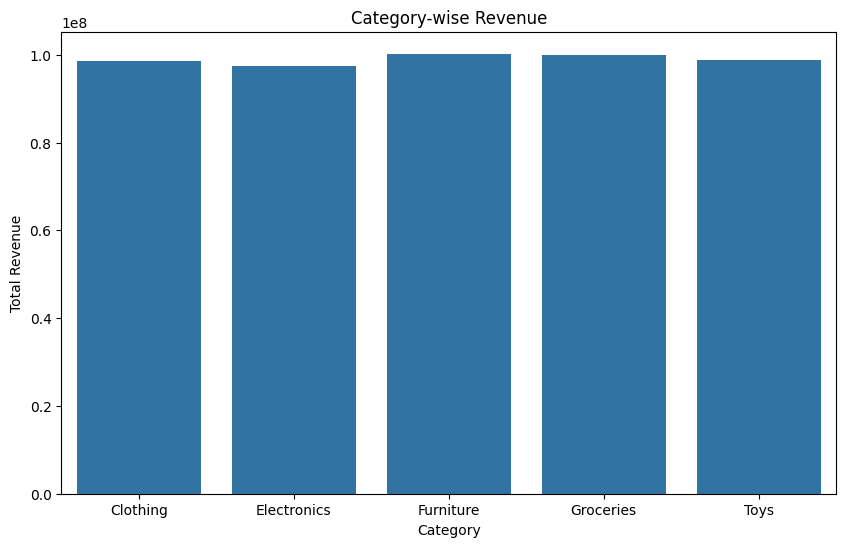

In [ ]:
#bar chart of Category-wise revenue
plt.figure(figsize=(10, 6))
sns.barplot(x=category_revenue.index, y=category_revenue.values)
plt.title('Category-wise Revenue')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.show()



1. Explain the Chart?

    This bar chart shows the total net revenue generated by each product category, including Clothing, Electronics, Furniture, Groceries, and Toys.
2. What is it saying?

    The chart shows that Furniture generates the highest revenue, while Electronics generates the lowest revenue. All five categories have nearly similar revenue.
3. What features did you use?
    
    I used the Category and Net Revenue columns from the dataset.
* **Category**: Product category name.
* **Net Revenue**: Revenue after deducting discounts.

This chart helps us compare the revenue performance of different product categories. It shows that all categories contribute almost equally to the total revenue, with Furniture performing slightly better than the others.

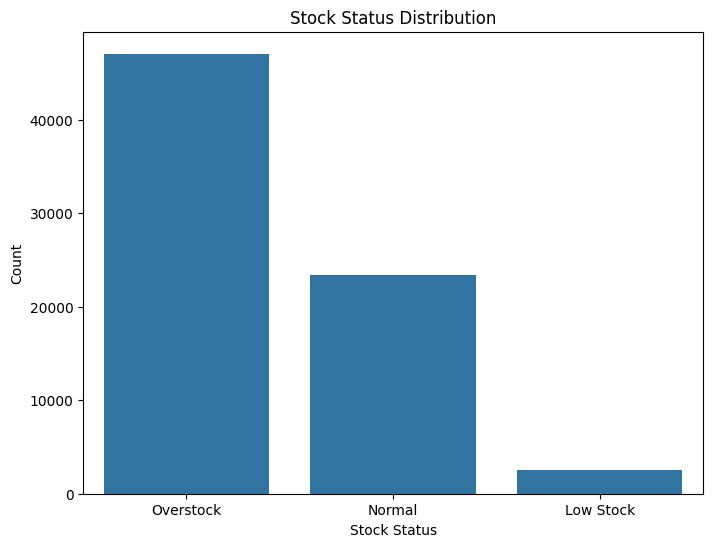

In [ ]:
# Countplot - Stock Status Distribution
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Stock Status')
plt.title('Stock Status Distribution')
plt.xlabel('Stock Status')
plt.ylabel('Count')
plt.show()

## Interpretation of your above chart

Explain the Chart.

This countplot shows the distribution of stock status in the retail inventory dataset. It represents three categories: Overstock, Normal, and Low Stock.

What is it saying?

The chart reveals that Overstock records dominate the inventory distribution, followed by Normal stock. Low Stock records represent only a small proportion of the dataset. This indicates an imbalance in inventory distribution, with excess stock being more common than stock shortages.

What features you used?

Stock Status: A newly created column that classifies inventory into three categories: Overstock, Normal, and Low Stock.

I used the Seaborn **countplot()** to visualize the number of records in each category.

From this what you are showing us?

The retail store should focus on reducing excess inventory by adjusting purchase quantities according to demand forecasts while maintaining sufficient stock to avoid shortages.


Text(0.5, 0, 'Units Sold')

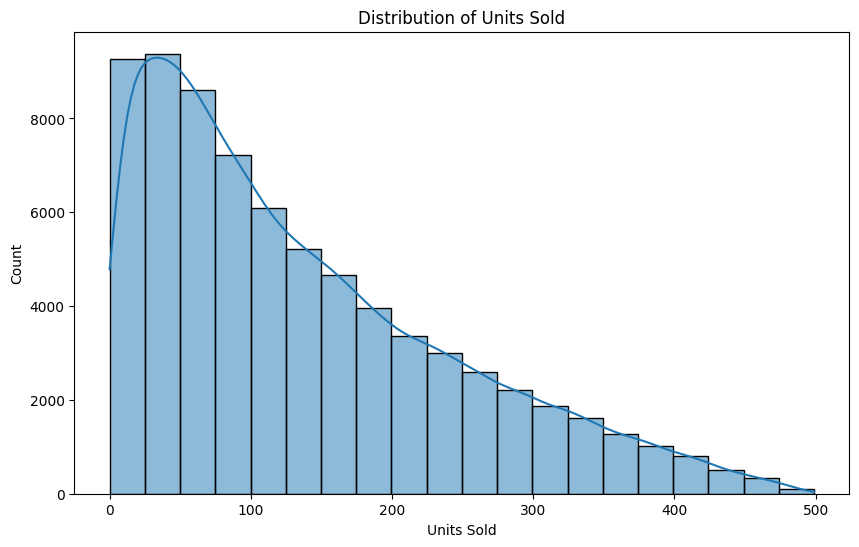

In [ ]:
# Histogram - Units Sold Distribution
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Units Sold', bins=20, kde=True)
plt.title('Distribution of Units Sold')
plt.xlabel('Units Sold')

## Interpretation of your above chart

Explain the Chart.

This histogram shows the distribution of units sold. It helps us understand how many products are sold in different quantity ranges. Most of the sales happen in the lower quantity range, and fewer sales happen in the higher quantity range.

What is it saying?

From this chart, we can see that most customers buy fewer units. Sales are higher between 0 and 100 units. As the number of units increases, the sales count gradually decreases. Very few customers buy more than 400 units.

What features you used?

I used a Histogram to show the distribution of units sold. I used bins=20 to divide the data into 20 groups. I also used kde=True to display a smooth curve that helps us understand the sales pattern. I used Matplotlib to add the chart title and X-axis label.

From this what you are showing us?

Based on this chart, the business should focus on increasing product sales. They can provide discounts and special offers to encourage customers to buy more products. They can also introduce bulk purchase offers to attract more customers. The business should maintain enough stock for products that sell frequently. This will help increase sales and improve business growth.

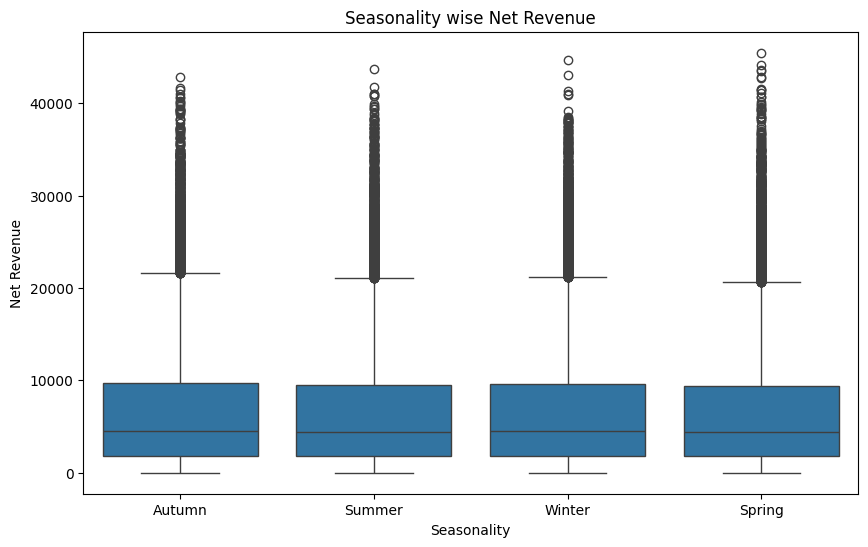

In [ ]:
# Boxplot - Seasonality wise Net Revenue
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Seasonality', y='Net_Revenue')
plt.title('Seasonality wise Net Revenue')
plt.xlabel('Seasonality')
plt.ylabel('Net Revenue')
plt.show()

## Interpretation of your above chart

Explain the Chart.

This boxplot shows the net revenue across four seasons: Autumn, Summer, Winter, and Spring. It helps us compare revenue in different seasons.

What is it saying?

From this chart, we can see that all four seasons have almost similar revenue patterns. Spring and Winter have slightly higher revenue values in some transactions. We can also see many high-revenue values in all seasons.

What features you used?

I used a Boxplot from the Seaborn library. I used x='Seasonality' to display the seasons and y='Net_Revenue' to show the revenue values. I also used Matplotlib to add the chart title and axis labels.

From this what you are showing us?

The chart shows that net revenue is almost similar across all four seasons. There is no major difference in the median revenue. However, all seasons have some high-revenue transactions.



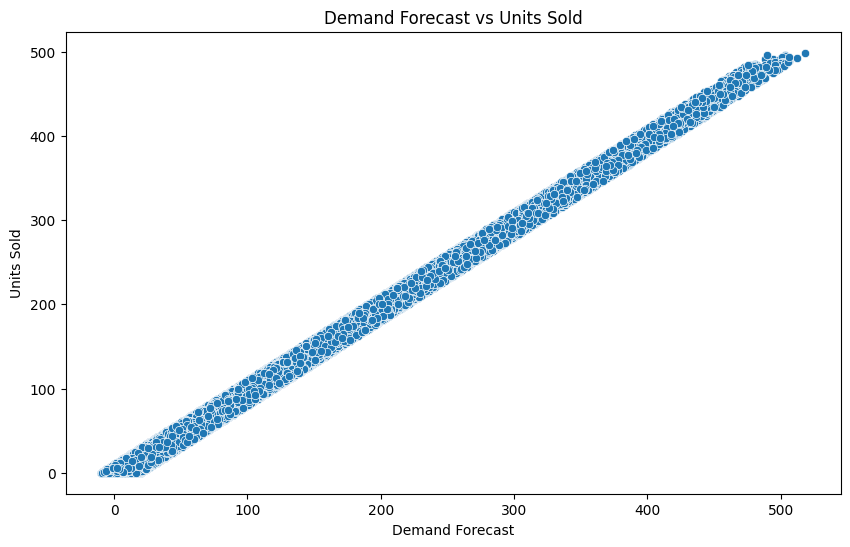

In [ ]:
# Scatterplot - Demand Forecast vs Units Sold
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Demand Forecast', y='Units Sold')
plt.title('Demand Forecast vs Units Sold')
plt.xlabel('Demand Forecast')
plt.ylabel('Units Sold')
plt.show()

## Interpretation of your above chart

Explain the Chart.

This scatterplot shows the relationship between Demand Forecast and Units Sold. It helps us understand how predicted demand is related to actual product sales.

What is it saying?

From this chart, we can see that when Demand Forecast increases, Units Sold also increases. The dots form an almost straight upward line, which indicates a strong positive relationship between both values.

What features you used?

I used a Scatterplot from the Seaborn library. I used x='Demand Forecast' to display the predicted demand and y='Units Sold' to display actual sales.

From this what you are showing us?

This chart shows that Demand Forecast and Units Sold have a strong positive relationship. When the predicted demand is high, the number of units sold is also high. This helps the business understand demand patterns and plan product stock accordingly.

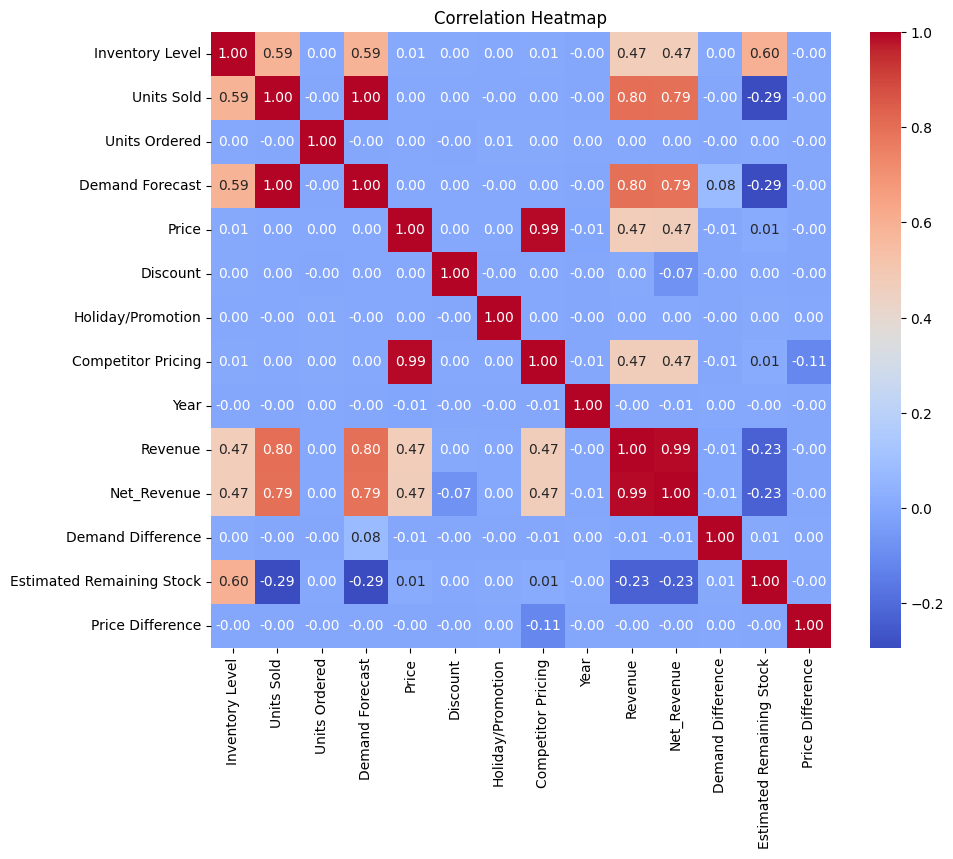

In [ ]:
# Correlation Heatmap
numeric_df = df.select_dtypes(include='number')
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## Interpretation of your above chart

Explain the Chart.

This Correlation Heatmap shows the relationship between different business factors such as Inventory Level, Units Sold, Demand Forecast, Price, Revenue, and Net Revenue. It helps us identify which factors are strongly or weakly related to each other.

What is it saying?

From this chart, we can see that Units Sold and Demand Forecast have a very strong positive relationship (1.00). Revenue and Net Revenue also have a strong relationship (0.99). Price and Competitor Pricing show a strong relationship (0.99). Inventory Level also has a positive relationship with Units Sold (0.59). This helps us understand how different business factors are connected.

What features/columns you used?

I used a Correlation Heatmap from the Seaborn library. I used select_dtypes(include='number') to select numerical columns and .corr() to calculate the correlation between them. I used sns.heatmap() with annot=True to display correlation values, cmap='coolwarm' to show different colours, and fmt='.2f' to display values up to two decimal places.

From this what you are showing us?

The business should focus on demand forecasting and inventory management to maintain sufficient stock. It should also monitor product prices and competitor prices to make better pricing decisions. By analysing sales and revenue patterns, the company can identify opportunities to improve sales and increase profit.

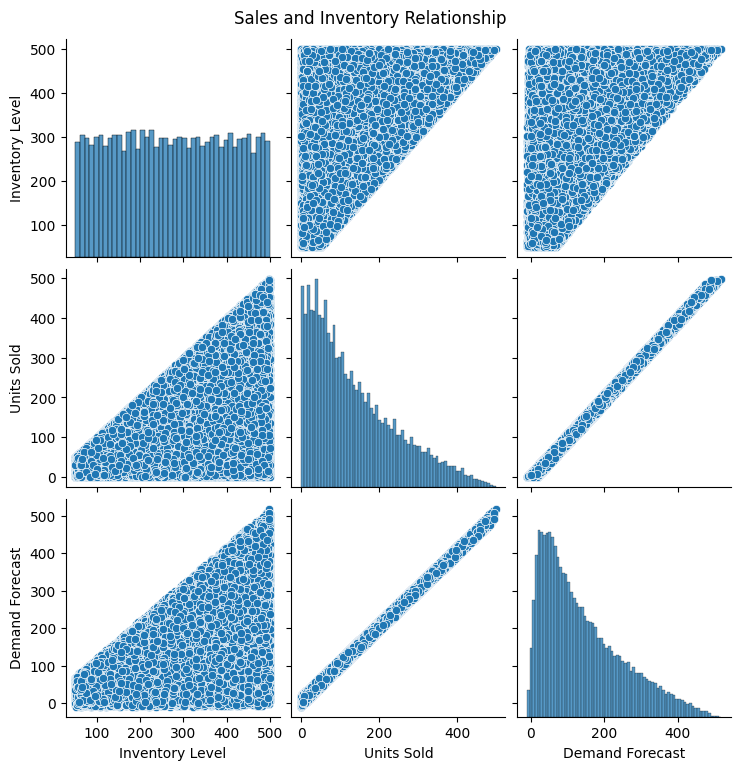

In [ ]:
# Pairplot
sns.pairplot(df[['Inventory Level', 'Units Sold', 'Demand Forecast']],
    diag_kind='hist')
plt.suptitle('Sales and Inventory Relationship', y=1.02)
plt.show()

## Interpretation of your above chart

Explain the Chart.

This Pairplot shows the relationship between three important business factors: Inventory Level, Units Sold, and Demand Forecast. It helps us understand how stock availability, product sales, and predicted demand are connected.

What is it saying?

From this chart, we can see that Units Sold and Demand Forecast have a strong positive relationship. When demand increases, units sold also increases. Inventory Level shows different sales patterns at different stock levels. The histograms show the distribution of each factor.

What features you used?

I used a Pairplot from the Seaborn library. I selected three numerical columns: Inventory Level, Units Sold, and Demand Forecast. I used diag_kind='hist' to display histograms on the diagonal and plt.suptitle() to add the overall chart title.

From this what you are showing us?

The business should maintain sufficient stock based on customer demand. When demand increases, the company should increase stock availability to avoid product shortages. It should also use demand forecasting to plan inventory properly. This will help improve sales and manage stock effectively.

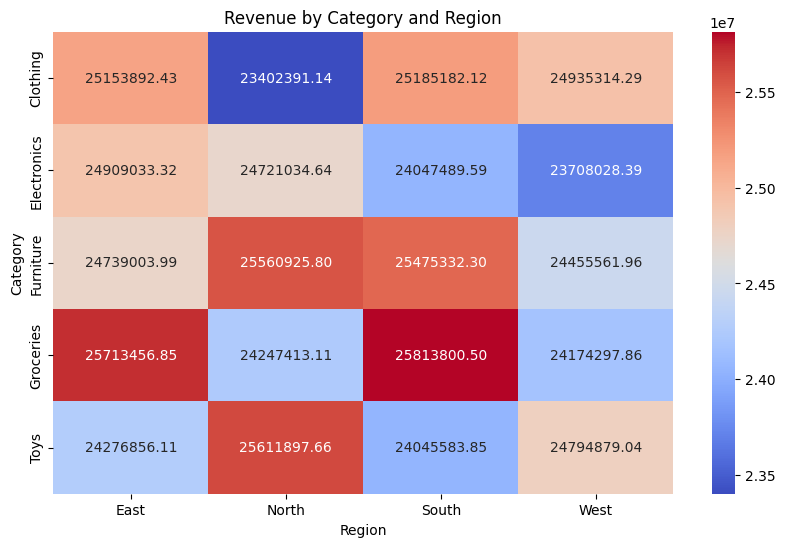

In [ ]:
# Grouped Analysis – Category, Region and Revenue
grouped_data = df.groupby(['Category', 'Region'])['Net_Revenue'].sum().reset_index()
pivot_table = grouped_data.pivot(index='Category', columns='Region', values='Net_Revenue')
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_table, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Revenue by Category and Region')
plt.show()


## Interpretation of your above chart

Explain the Chart.

This heatmap shows the total revenue generated by five product categories across four regions: East, West, North, and South. It helps us compare the revenue of different categories in different regions.

What is it saying?

From this chart, we can see that Groceries in the South region has the highest revenue. Toys in the North region and Furniture in the North region also show good revenue. Electronics in the West region has comparatively lower revenue. Overall, revenue is almost similar across all categories and regions.

What features you used?

I used a Heatmap from the Seaborn library. I used groupby() to group the data by Category and Region, and sum() to calculate total Net Revenue. I used pivot() to arrange the data into a table format. I used sns.heatmap() with annot=True to display revenue values and cmap='coolwarm' to show different colours.

From this what you are showing us?

The business should focus on high-revenue categories like Groceries in the South region and Toys in the North region. It should improve marketing activities for categories with comparatively lower revenue, especially Electronics in the West region. The company can also introduce regional offers and promotions to increase sales and revenue in every region.



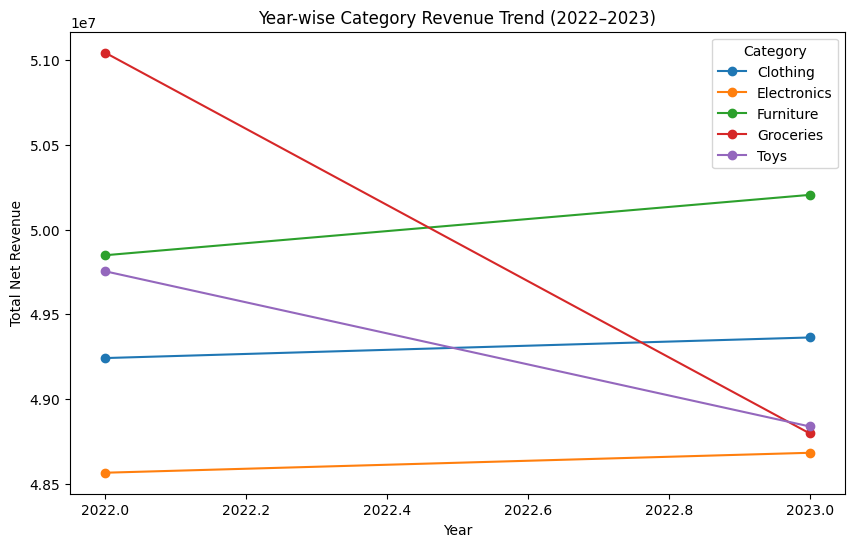

In [ ]:
# Pivot Table- year vs Category – Total Revenue in line chart
df_full_years = df[df['Year'].isin([2022, 2023])]
pivot_table = pd.pivot_table(df_full_years,index='Year',columns='Category',values='Net_Revenue',aggfunc='sum')
pivot_table.plot(kind='line',figsize=(10, 6),marker='o')
plt.title('Year-wise Category Revenue Trend (2022–2023)')
plt.xlabel('Year')
plt.ylabel('Total Net Revenue')
plt.show()


## Interpretation of your above chart

Explain the Chart.

This line chart shows the total net revenue of five product categories (Clothing, Electronics, Furniture, Groceries, and Toys) for the years 2022 and 2023. It helps us compare the revenue performance of each category.

What is it saying?

From this chart, we can see that Furniture revenue slightly increased in 2023. Clothing and Electronics also show a small increase. But Groceries and Toys revenue decreased in 2023. Groceries had the highest revenue in 2022, while Furniture had the highest revenue in 2023.

What features you used?

I used a Line Chart to show the yearly revenue trend. I used df['Year'].isin([2022, 2023]) to select data for 2022 and 2023. I used pivot_table() to group revenue by year and category, and aggfunc='sum' to calculate total net revenue. I used plot(kind='line', marker='o') to create the line chart with markers.

From this what you are showing us?

The business should focus on improving sales in Groceries and Toys because their revenue decreased in 2023. It should continue supporting Furniture, Clothing, and Electronics because their revenue increased. The company can introduce special offers and improve marketing strategies for categories with decreasing revenue to increase sales and profit.

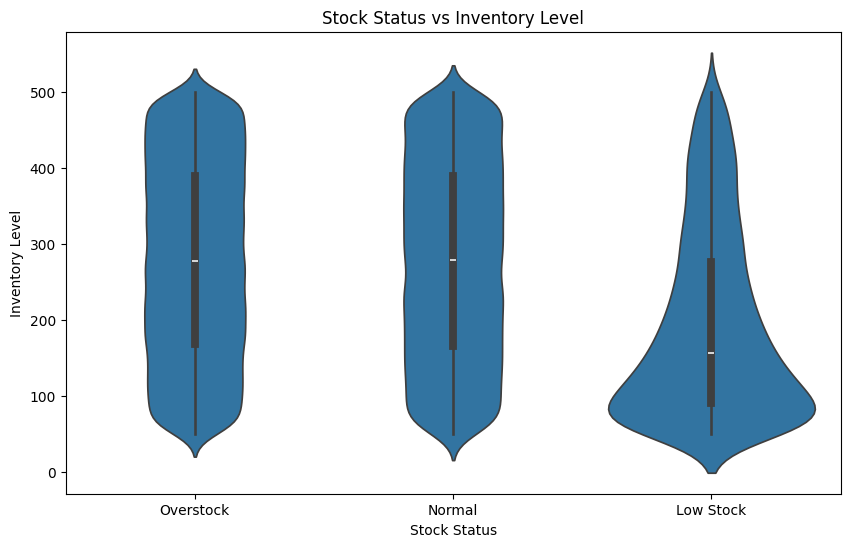

In [ ]:
# Violin Plot – Stock Status vs Inventory Level
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='Stock Status', y='Inventory Level')
plt.title('Stock Status vs Inventory Level')
plt.xlabel('Stock Status')
plt.ylabel('Inventory Level')
plt.show()


## Interpretation of your above chart

Explain the Chart.

This violin plot shows the Inventory Level for three stock statuses: Overstock, Normal, and Low Stock. It helps us understand how inventory levels are distributed in each stock category.

What is it saying?

From this chart, we can see that Overstock and Normal categories have higher inventory levels. The Low Stock category has mostly lower inventory levels. This shows that some products have excess stock, while some products have less stock available.

What features you used?

I used a Violin Plot from the Seaborn library. I used x='Stock Status' to display the stock categories and y='Inventory Level' to show inventory quantities. I used plt.figure() to set the chart size, plt.title() to add the chart title, and plt.xlabel() and plt.ylabel() to label the axes.

From this what you are showing us?

The business should reduce excess stock in the Overstock category and increase stock in the Low Stock category. It should maintain proper inventory levels in the Normal category. This will help avoid product shortages, reduce storage costs, and manage inventory effectively.

## **Download cleaned data for dashboard creation using Power BI**


In [ ]:
# Export cleaned dataset
df.to_csv('retail_store_cleaned.csv', index=False)

In [ ]:
# Download CSV file
from google.colab import files
files.download('retail_store_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

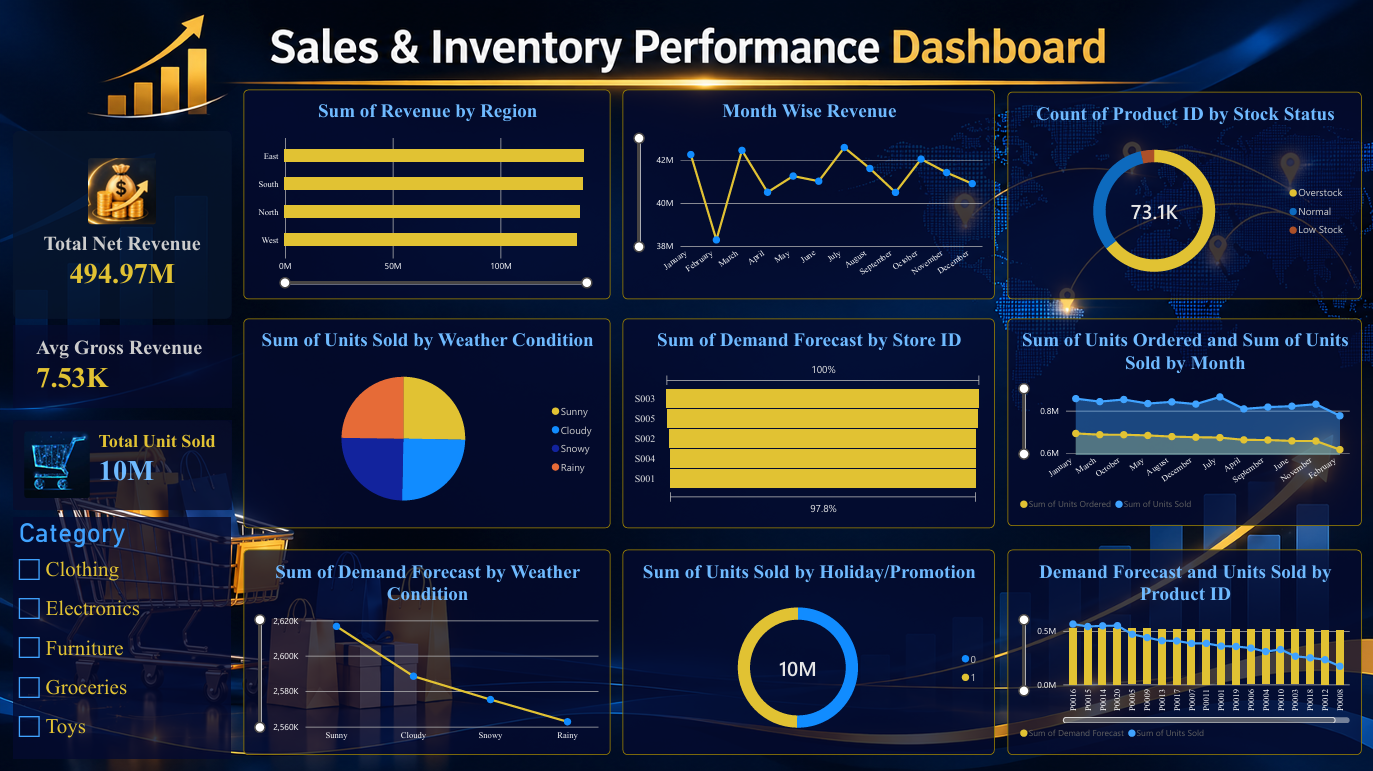

**Documentation link:** https://drive.google.com/drive/folders/1ngN7Qkmu1wI2ohWEzGUkyGC7JDGvhsF-?usp=sharing

## Stage 4 – Documentation, Insights and Presentation

Show a dashboard aligning all the charts in powerbi by connecting python in PowerBI

Summarize findings in plain English (what do the patterns mean)

Highlight 3–5 key insights (trends, anomalies, correlations)

Provide recommendations for business or decision-making

Explain the FINAL STORY WITH THE DASHBOARD/report

Create a PDF pasting your DASHBOARD, explaining all the above mentioned concepts and submit it


## **Final Overall Insights:**
Final Overall Insights – Retail Store Dashboard
- **Descriptive (What happened):** The retail store generated 494.97M total net revenue, with an average gross revenue of 7.53K and 10M total units sold. Revenue is analyzed across four regions, and monthly revenue shows business performance over time.

- **Diagnostic (Why it happened):** Sales and demand vary across different weather conditions (Sunny, Cloudy, Snowy, and Rainy). Regional revenue, holiday promotions, and product-wise sales help identify factors influencing business performance.

- **Predictive (What may happen):** Demand forecasting across stores and products helps predict future customer demand. If current patterns continue, businesses can use these forecasts to plan stock requirements and anticipate sales trends.

- **Prescriptive (What to do):** Maintain optimal inventory levels, reduce overstock and low-stock situations, improve demand forecasting, and plan stock replenishment based on product demand and seasonal trends.

# Future Enhancement

1. Larger Dataset: Use a larger and more recent retail dataset to gain deeper insights into sales and inventory performance.

2. Automation: Automate data cleaning and analysis using Python scripts to reduce manual work.

3. Advanced Dashboard: Enhance the Power BI dashboard with advanced visualizations and interactive filters.

4. Predictive Analysis: Implement Machine Learning techniques to forecast future sales and product demand.

5. Real-Time Monitoring: Integrate real-time inventory data to identify stock shortages and overstock situations.

# Conclusion

This project successfully analyzed retail sales and inventory data using Python and Power BI. It identified important sales trends, revenue performance, and stock management issues through data analysis and visualizations. The insights help businesses improve inventory planning, understand customer demand, and make better data-driven decisions.